### Add ACT into environment

In [1]:
# Setup and imports
from pathlib import Path
import sys, os


act_root = os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath('__file__'))))
sys.path.insert(0, act_root) if act_root not in sys.path else None

ACT_ROOT = Path(act_root)

### Initialise `device` and `dtype` for PyTorch

In [2]:
from act.util.device_manager import initialize_device


DEVICE = "mps"
DTYPE = "float32"

initialize_device(device=DEVICE, dtype=DTYPE)

✅ Device Manager Initialized: device=mps, dtype=torch.float32, tf32=off


### Set up concept dataset and model

In [3]:
# Initialise regular and bottleneck models
import pickle
from pytorchcv.model_provider import get_model
import torch
import torchvision.transforms as transforms

from act.front_end.torchvision_loader.data_model_loader import _resolve_external_dataset
from act.front_end.torchvision_loader.data_model_mapping import DATASET_MODEL_MAPPING
from ipynb.slcbm.src.dataset import ConceptBank, ConceptDataset
from ipynb.slcbm.src.model import SLCBM, ConceptOnlySLCBM, ResNetBottom


BACKBONE_ROOT = ACT_ROOT / "data/torchvision/CUB200/models"
CONCEPT_BANKS_PATH = ACT_ROOT / "ipynb/slcbm/data/cub_resnet18_cub_0.01_100.pkl"
CUB_WEIGHTS_PATH = ACT_ROOT / "ipynb/slcbm/data/tuned_weights.pt"

BATCH_SIZE = 1
DATASET_NAME = "CUB200"
CUB_MEAN = [0.5, 0.5, 0.5]
CUB_STD = [2.0, 2.0, 2.0]

# Set up testing CUB dataset, using ACT-internal functions
dataset_info = DATASET_MODEL_MAPPING[DATASET_NAME]

transform = transforms.Compose([
    transforms.CenterCrop(size=(224, 224)),
    transforms.ToTensor()
])

images_and_classes = _resolve_external_dataset(
    dataset_info=dataset_info,
    raw_dir = ACT_ROOT / "data/torchvision/CUB200/raw",
    transform=transform,
    train=False,
)
concepts: list[torch.Tensor] = pickle.load(open(ACT_ROOT / "ipynb/slcbm/data/train_312.pkl", "rb"))
dataset = ConceptDataset(images_and_classes, concepts)

# Set up concept bottleneck model
backbone_model = get_model(
    name="resnet18_cub",
    pretrained=True,
    root=BACKBONE_ROOT
)

backbone = ResNetBottom(backbone_model)
backbone.to(device=DEVICE).eval()
backbone.encode_image = lambda image: backbone(image)

normalizer = transforms.Normalize(mean=CUB_MEAN, std=CUB_STD)

with open(CONCEPT_BANKS_PATH, "rb") as f:
    concept_dict = pickle.load(f)

concept_bank = ConceptBank(
    concept_dict=concept_dict,
    device=torch.float32
)

bottleneck_model = SLCBM(
    backbone=backbone,
    normalizer=normalizer,
    concept_bank=concept_bank,
    num_classes=200
)

state_dict = torch.load(CUB_WEIGHTS_PATH, weights_only=True, map_location=torch.device(DEVICE))
bottleneck_model.load_state_dict(state_dict, strict=False)
bottleneck_model.to(device=DEVICE)
bottleneck_model.train(False)

concept_model = ConceptOnlySLCBM(bottleneck_model)

Concept Bank is initialized.


### Set up list of attributes and categories

In [4]:
# Initialise mapping between concept bank indices and human-readable names

# Open attributes.txt in `CUB_DATASET`
from ipynb.slcbm.src.dataset import CUB_features


attributes_path = ACT_ROOT / "data/torchvision/CUB200/raw/attributes.txt"

all_attributes = []
with open(attributes_path, "r") as f:
    for line in f:
        attribute = line.strip()
        all_attributes.append(attribute.split()[1])

SLCBM_CUB_ATTRIBUTES: list[str] = all_attributes

# All categories are class variables in `CUB_features`, and start with `has_`
all_categories = []

for cub_features_var in CUB_features.__dict__:
    if not cub_features_var.startswith("has_"):
        continue

    category_bounds: tuple[int, int] = getattr(CUB_features, cub_features_var)
    category_range = list(range(category_bounds[0], category_bounds[1] + 1))
    all_categories.append(category_range)

CUB_CATEGORIES: list[list[int]] = all_categories

### Generate spec pairs

[ACT] Auto-detecting project root: ../..
[ACT] Gurobi license found: ../../modules/gurobi/gurobi.lic
tensor(0, device='mps:0')
tensor(5, device='mps:0')
tensor(4, device='mps:0')
tensor(6, device='mps:0')
tensor(3, device='mps:0')
tensor(6, device='mps:0')
tensor(1, device='mps:0')
tensor(2, device='mps:0')
Generating specs for cub200, slcbm-resnet18


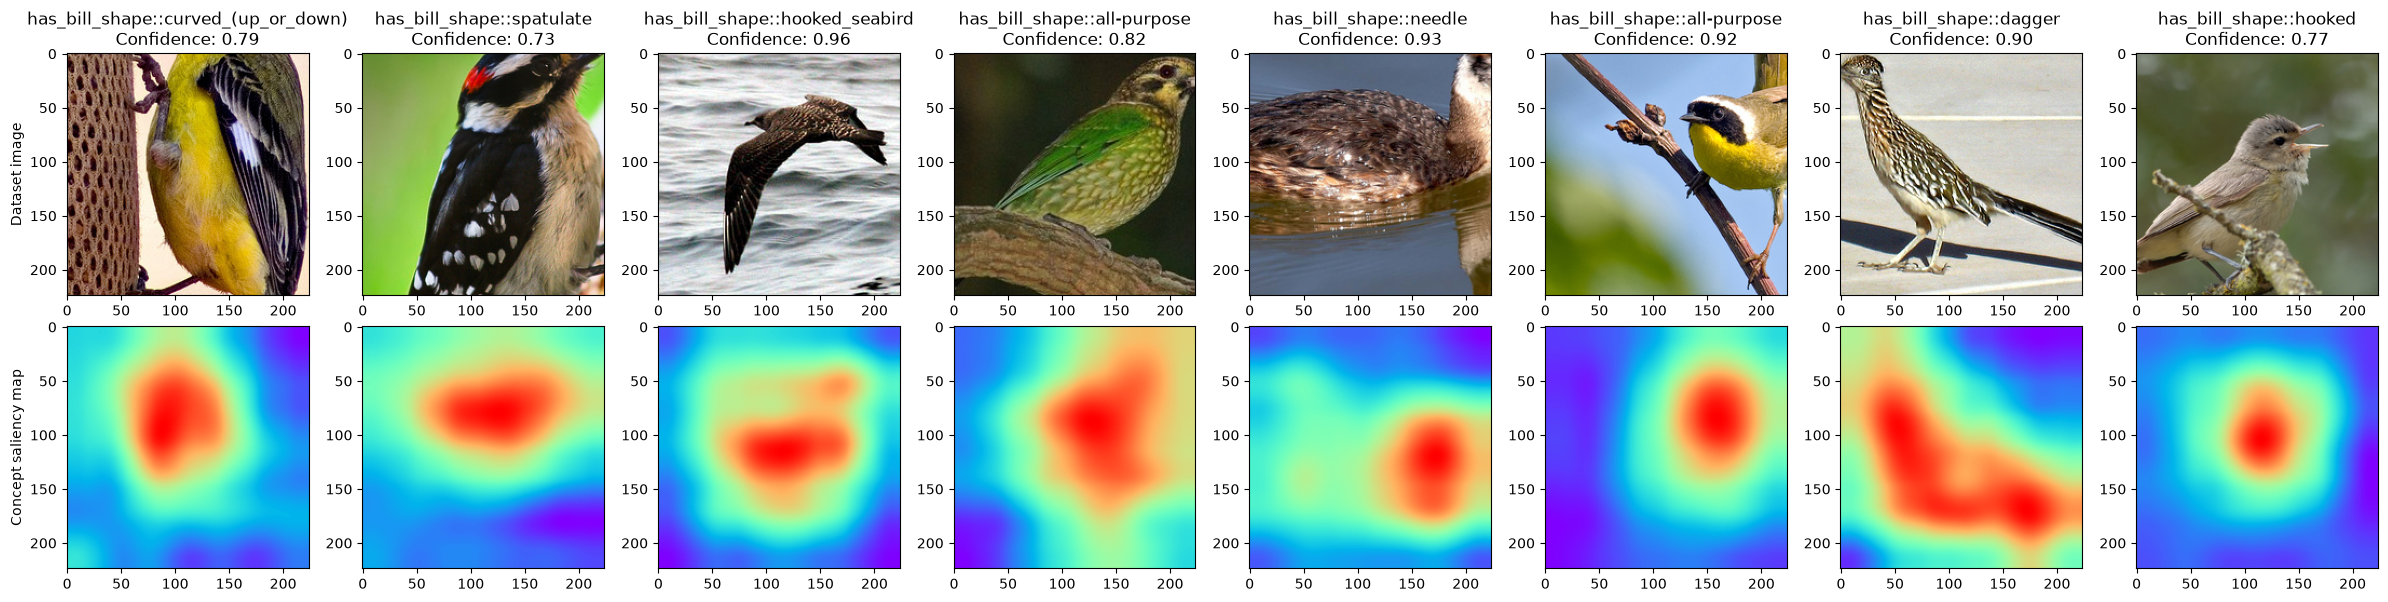


🧬 Synthesizing models from 1 spec result(s)...

🎉 Synthesis Complete:
   Total specs: 32
   Wrapped models: 1


In [5]:
from collections import OrderedDict
from matplotlib import pyplot as plt
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, RandomSampler

from act.front_end.concept.create_specs import ConceptSpecCreator
from act.front_end.model_synthesis import synthesize_models_from_specs
from act.front_end.specs import OutKind


NUM_SAMPLES = 8
EPSILONS = [0.01, 0.03, 0.05, 0.1]

RAINBOW_MAP = plt.get_cmap("rainbow")


class ImageMaskDataset(Dataset):
    def __init__(self, img_mask_tuples: list[tuple[torch.Tensor, torch.Tensor, torch.Tensor]]):
        self.img_mask_tuples = img_mask_tuples

    def __len__(self):
        return len(self.img_mask_tuples)

    def __getitem__(self, index) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        return self.img_mask_tuples[index]


# Set up concept spec creator
spec_creator = ConceptSpecCreator(
    spec_kinds=[OutKind.CONCEPT_TOP_IN_CATEGORY],
    epsilons=EPSILONS,
    categories=CUB_CATEGORIES,
)

# Set up concept dataloader (returns `(image, mask, target)`)
sampler = RandomSampler(dataset, num_samples=NUM_SAMPLES, generator=torch.Generator(device=DEVICE))
sampled_dataloader = DataLoader(dataset, sampler=sampler)

img_mask_tuples: list[tuple[torch.Tensor, torch.Tensor, torch.Tensor]] = []

# Display images and saliency maps corresponding with top concepts
fig, axs = plt.subplots(2, NUM_SAMPLES, figsize=(NUM_SAMPLES * 3, 6))
axs[0, 0].set_ylabel("Dataset image")
axs[1, 0].set_ylabel("Concept saliency map")

for index, (image, label) in enumerate(sampled_dataloader):
    _, concept_probs, saliency_maps = bottleneck_model(image.to(device=DEVICE))
    y_true = concept_probs[:, :8].argmax()
    print(y_true)

    saliency_map = saliency_maps.detach().permute(0, 3, 1, 2)[0, y_true].unsqueeze(0).unsqueeze(0)
    scaled_map = F.interpolate(saliency_map, size=(224, 224), mode="bicubic").squeeze()
    
    # Normalise map
    s_min, s_max = scaled_map.min(), scaled_map.max()
    norm_map = (scaled_map - s_min) / (s_max - s_min)

    axs[0, index].set_title(f"{SLCBM_CUB_ATTRIBUTES[y_true]}\nConfidence: {concept_probs[0, y_true].item():.2f}")
    axs[0, index].imshow(image.squeeze().permute(1, 2, 0).cpu().numpy())
    
    heatmap = RAINBOW_MAP(norm_map.detach().cpu().numpy())
    axs[1, index].imshow(heatmap)

    img_mask_tuples.append((image.squeeze(), norm_map.unsqueeze(0).repeat(3, 1, 1), y_true))

img_mask_dataset = ImageMaskDataset(img_mask_tuples)
dataloader = DataLoader(img_mask_dataset)

# Set up ordered dicts for both dataloaders and models
dataloaders = OrderedDict()
dataloaders["cub200"] = (dataloader, 312)

models = OrderedDict()
models["slcbm-resnet18"] = concept_model

specs = spec_creator.create_specs_for_data_model_pairs(
    dataloaders=dataloaders,
    models=models,
    num_samples=NUM_SAMPLES,
)

plt.tight_layout()
plt.show()

synth_models = synthesize_models_from_specs(specs)

### Fuzzing

In [6]:
# ACT fuzzing config
from act.front_end.concept.output_spec import TopInCategory
from act.front_end.spec_creator_base import LabeledInputTensor
from act.front_end.verifiable_model import InputLayer, InputSpecLayer, OutputSpecLayer, VerifiableModel
from act.pipeline.fuzzing.actfuzzer import ACTFuzzer, FuzzingConfig


config_path = Path(ACT_ROOT) / "act/config/pipeline.yaml"
config = FuzzingConfig.from_yaml(
    config_path=config_path,
    timeout_seconds=60.0,
    report_interval=32,
    verbose=1,
    # Tracing: capture execution traces for analysis
    trace_level=1,
    trace_storage='json'
)

# List of top concepts for each input-output spec pair, for each batched model (2D array)
all_top_concepts: list[torch.Tensor] = []
all_fuzzers: list[ACTFuzzer] = []

# Iterate over wrapped models for fuzzing results
for item in synth_models.items():
    model: VerifiableModel = item[1] # type: ignore

    input_layer: InputLayer = model.input_layer
    labeled_input = input_layer.labeled_input

    input_spec_layer: InputSpecLayer = model.input_spec
    input_spec = input_spec_layer.spec

    output_spec_layer: OutputSpecLayer = model.output_spec
    output_spec: TopInCategory = output_spec_layer.spec

    images = labeled_input.tensor.to(DEVICE)

    assert labeled_input.label is not None
    labels = labeled_input.label.to(DEVICE)

    # ACT now combines models, thus we need to infer the new batch size of that
    # synthesised model and change seeds (which expect only one class label) accordingly
    batch_size = images.shape[0]

    initial_seeds = [
        LabeledInputTensor(tensor=images[i:i+1], label=labels[i:i+1])
        for i in range(batch_size)
    ]

    all_top_concepts.append(output_spec.top_elements)

    fuzzer = ACTFuzzer(
        wrapped_model=model,
        initial_seeds=initial_seeds,
        config=config
    )
    
    fuzzer.fuzz()
    all_fuzzers.append(fuzzer)

📊 Tracing enabled: Level 1, sampling every 1 iteration(s)
   Output: ../../act/pipeline/log/fuzzing_results/traces_0.json
ACT: Abstract Constraint Transformer
Inference-based whitebox fuzzing for neural network verification

🚀 Starting ACTFuzzer with 32 seeds
   Device: mps:0
   Batch size: 32 (from model synthesis)
   Max iterations: 10000
   Timeout: 60.0s

📊 Iteration     32 | GlobalCov: 92.13% BestInputCov: 66.32% | Seeds:   64 | Violations:   0 (+0) | Speed:  26.4 it/s (845 samples/s)
📊 Iteration     64 | GlobalCov: 92.19% BestInputCov: 66.32% | Seeds:   73 | Violations:   0 (+0) | Speed:  12.7 it/s (408 samples/s)
📊 Iteration     96 | GlobalCov: 92.20% BestInputCov: 66.33% | Seeds:   78 | Violations:   0 (+0) | Speed:  10.9 it/s (349 samples/s)
📊 Iteration    128 | GlobalCov: 93.18% BestInputCov: 66.33% | Seeds:  110 | Violations:  28 (+28) | Speed:   6.9 it/s (219 samples/s)
📊 Iteration    160 | GlobalCov: 93.53% BestInputCov: 66.61% | Seeds:  142 | Violations:  59 (+31) | Speed

### Generate outputs

Found trace file: /Users/z5360341/Desktop/research/ACT/act/pipeline/log/fuzzing_results/traces_0.json


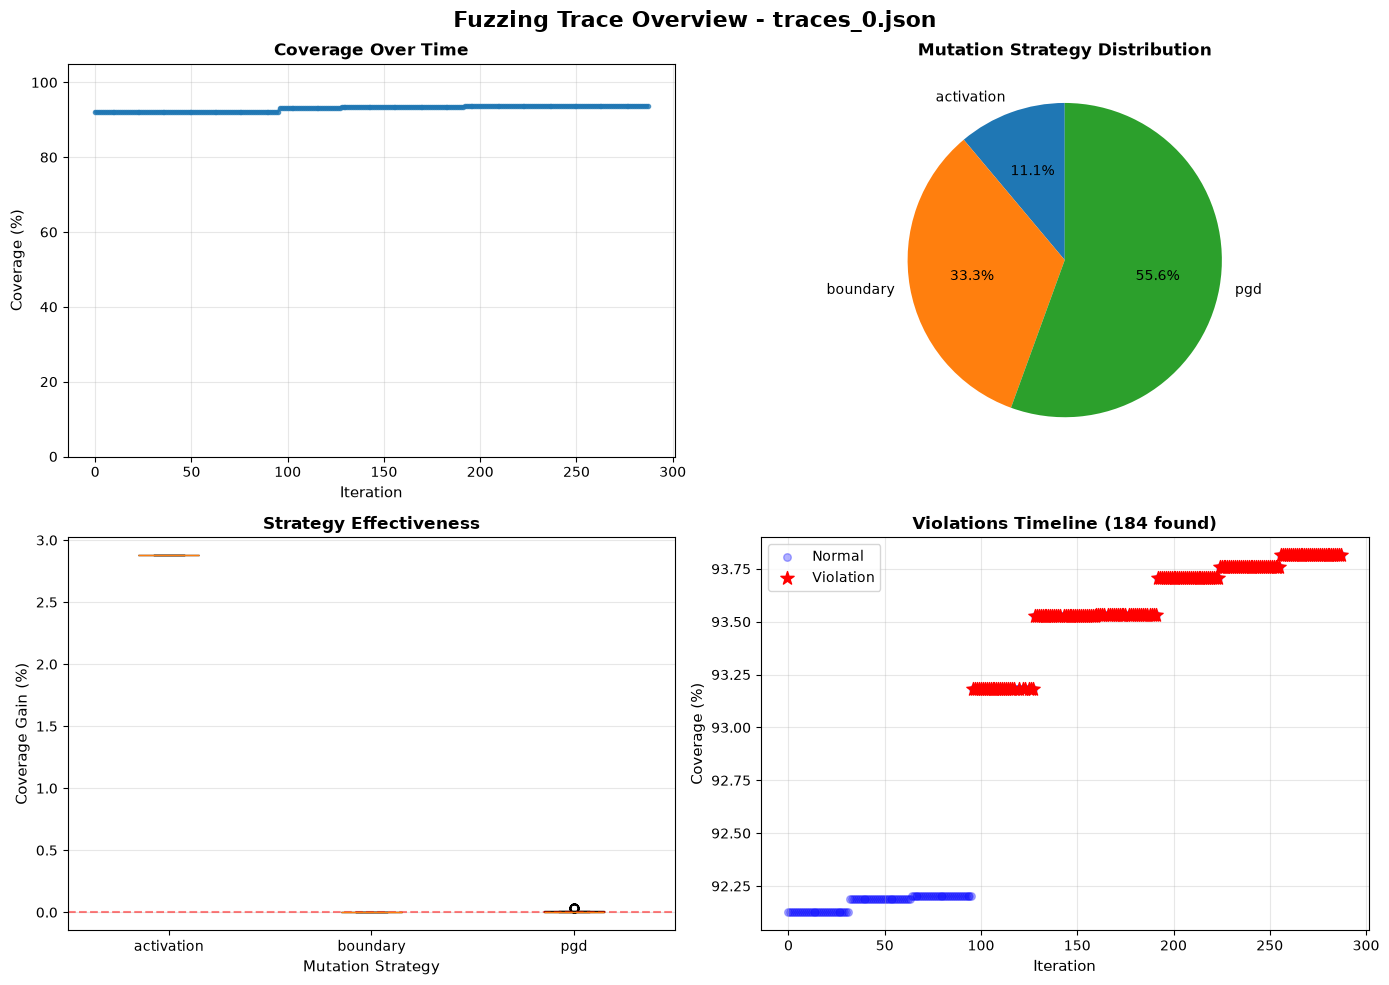

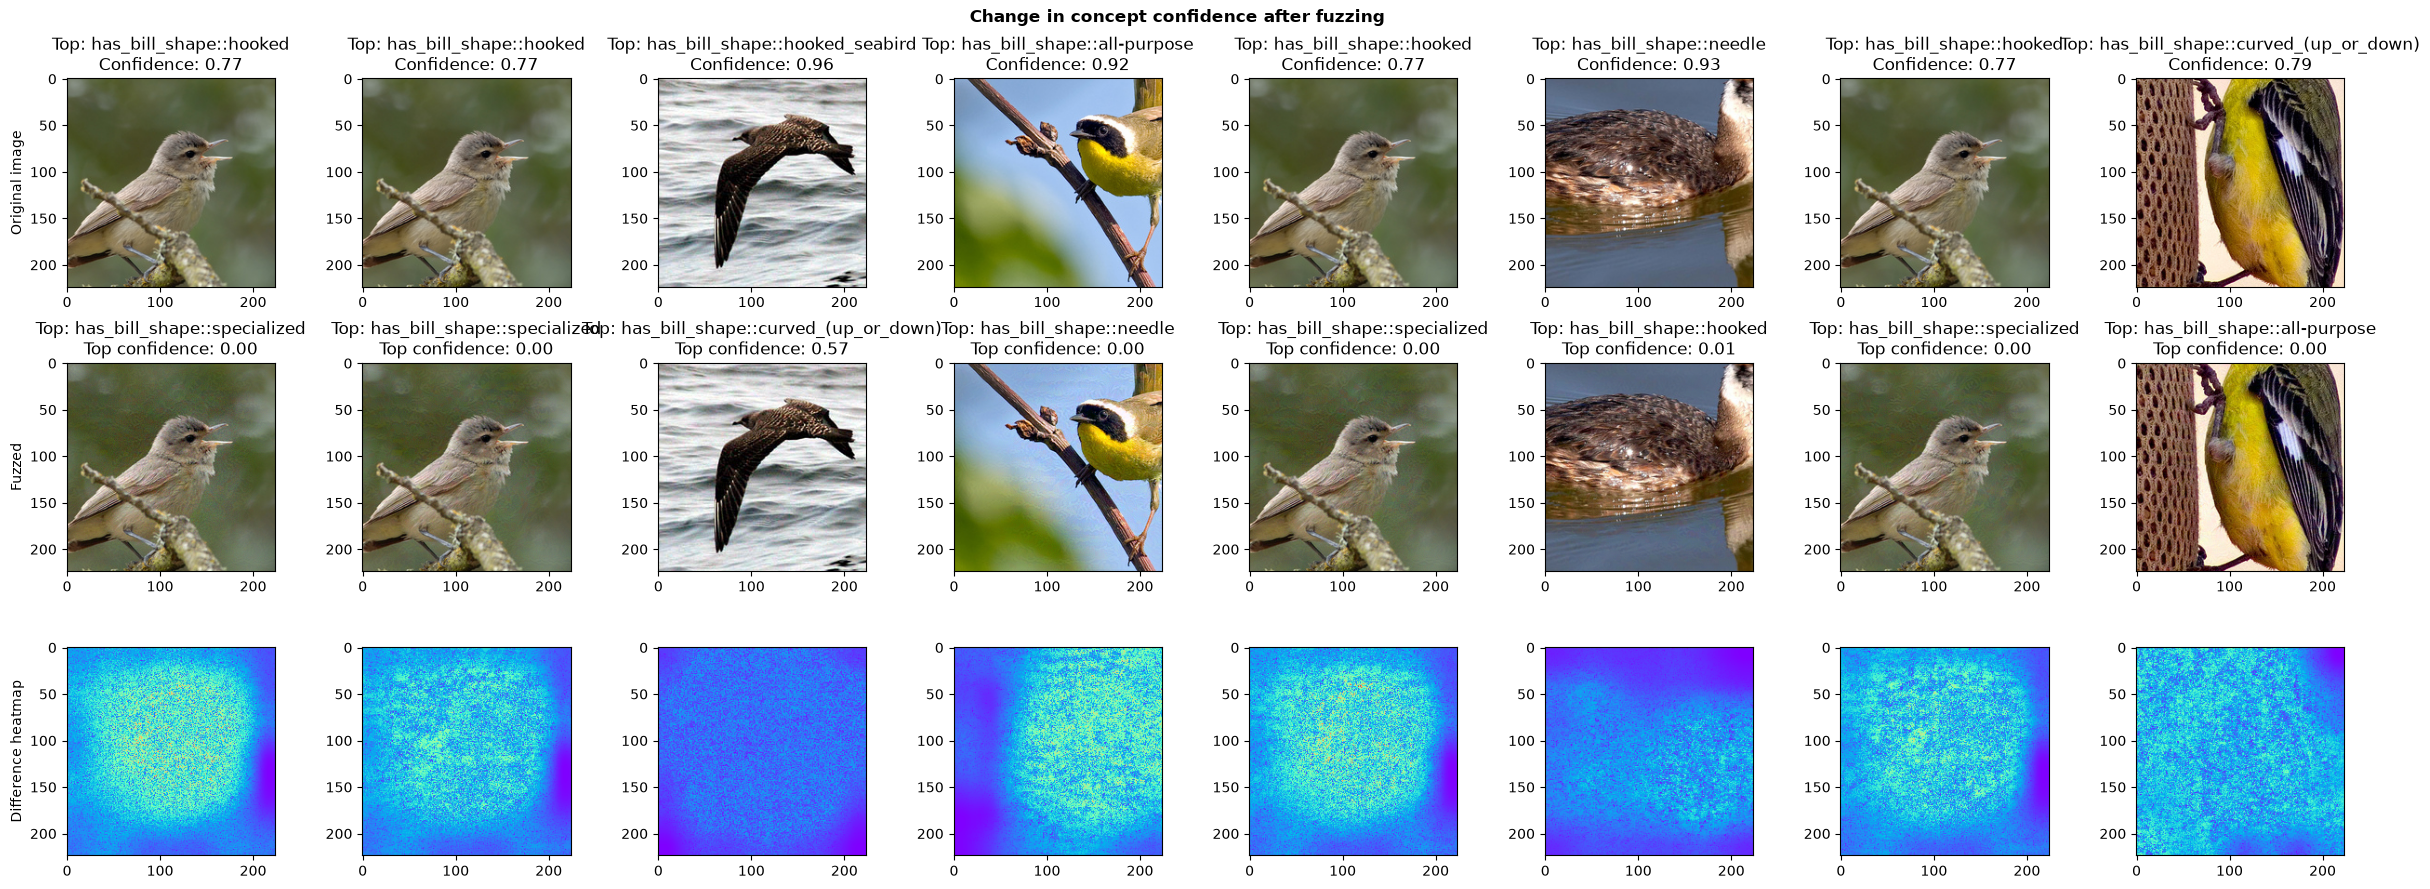

In [7]:
# Generate report from traces
import torch.nn.functional as F

from act.pipeline.fuzzing.trace_reader import TraceAnalyzer


NUM_TRACES = 8

trace_files = []

for fuzzer in all_fuzzers:
    if fuzzer.tracer is not None:
        trace_path = fuzzer.tracer.output_path

        if trace_path.exists():
            trace_files.append(trace_path)
            print(f"Found trace file: {trace_path}")

if len(trace_files) > 0:
    for index, file in enumerate(trace_files):
        top_concepts = all_top_concepts[index]
        fuzzer = all_fuzzers[index]

        # Summary plot
        analyzer = TraceAnalyzer(file)

        try:
            analyzer.plot_overview()
        except Exception as e:
            print(f"Could not generate plots: {e}")

        # Plot last `NUM_SAMPLES`
        traces = analyzer.traces

        fig, axs = plt.subplots(3, NUM_TRACES, figsize=(NUM_TRACES * 3, 9))

        axs[0, 0].set_ylabel("Original image")
        axs[1, 0].set_ylabel("Fuzzed")
        axs[2, 0].set_ylabel("Difference heatmap")
        
        for sample in range(NUM_TRACES):
            # Extract top `has_bill_shape` concept (based on ground-truth) and compare its
            # confidence with results after fuzzing
            bill_shape_min, bill_shape_max = CUB_features.has_bill_shape

            trace = traces[-(NUM_TRACES - sample)]
            seed_id = int(trace["seed_id"])

            # Index of said seed in seed corpus
            original_index: int = (fuzzer.seed_corpus._ids == seed_id).nonzero().item() # type: ignore
            # Use that to get the index of seed image in fuzzer inputs
            image_index = fuzzer.seed_corpus._original_indices[original_index]

            top_concept = top_concepts[image_index, 0]

            input_before: torch.Tensor = fuzzer.seed_corpus._original_tensors[original_index].unsqueeze(0)
            bill_concept_before: torch.Tensor = concept_model(input_before).squeeze()[bill_shape_min:bill_shape_max + 1]

            axs[0, sample].set_title(f"Top: {SLCBM_CUB_ATTRIBUTES[top_concept]}\n" \
                                     f"Confidence: {bill_concept_before[top_concept]:.2f}")
            axs[0, sample].imshow(input_before.squeeze().permute(1, 2, 0).cpu().numpy())

            input_after: torch.Tensor = trace["input_after"]
            bill_concept_after: torch.Tensor = concept_model(input_after).squeeze()[bill_shape_min:bill_shape_max + 1]
            bill_concept_after_max = int(bill_concept_after.argmax().item())

            axs[1, sample].set_title(f"Top: {SLCBM_CUB_ATTRIBUTES[bill_concept_after_max]}\n" \
                                     f"Top confidence: {bill_concept_after[top_concept]:.2f}")
            axs[1, sample].imshow(input_after.squeeze().permute(1, 2, 0).cpu().numpy())

            difference = (input_after - input_before).squeeze().norm(dim=0) / 0.1
            heatmap = RAINBOW_MAP(difference.cpu().numpy())
            axs[2, sample].imshow(heatmap)

        plt.suptitle(f"Change in concept confidence after fuzzing", fontsize=12, fontweight="bold")
        plt.tight_layout()
        plt.show()